In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [64]:
columns = [
    "open_time",
    "open",
    "high",
    "low",
    "close",
    "volume",
    "close_time",
    "quote_volume",
    "number_of_trades",
    "taker_buy_base_volume",
    "taker_buy_quote_volume",
    "ignore"
]

df = pd.read_csv(
    "../data/raw/BRDBTC-1m-2018-12.csv",
    names=columns
)

df.head()

,open_time,open,high,low,close,volume,close_time,quote_volume,number_of_trades,taker_buy_base_volume,taker_buy_quote_volume,ignore
0,1543622400000,0.000056,0.000056,0.000056,0.000056,446.0,1543622459999,0.025045,9,242.0,0.013591,0
1,1543622460000,0.000056,0.000056,0.000056,0.000056,5143.0,1543622519999,0.288008,3,0.0,0.000000,0
2,1543622520000,0.000056,0.000056,0.000056,0.000056,1637.0,1543622579999,0.091599,11,180.0,0.010081,0
3,1543622580000,0.000056,0.000056,0.000056,0.000056,0.0,1543622639999,0.000000,0,0.0,0.000000,0
4,1543622640000,0.000056,0.000056,0.000056,0.000056,70.0,1543622699999,0.003905,1,0.0,0.000000,0


In [65]:
df.head()

,open_time,open,high,low,close,volume,close_time,quote_volume,number_of_trades,taker_buy_base_volume,taker_buy_quote_volume,ignore
0,1543622400000,0.000056,0.000056,0.000056,0.000056,446.0,1543622459999,0.025045,9,242.0,0.013591,0
1,1543622460000,0.000056,0.000056,0.000056,0.000056,5143.0,1543622519999,0.288008,3,0.0,0.000000,0
2,1543622520000,0.000056,0.000056,0.000056,0.000056,1637.0,1543622579999,0.091599,11,180.0,0.010081,0
3,1543622580000,0.000056,0.000056,0.000056,0.000056,0.0,1543622639999,0.000000,0,0.0,0.000000,0
4,1543622640000,0.000056,0.000056,0.000056,0.000056,70.0,1543622699999,0.003905,1,0.0,0.000000,0


In [66]:
df["datetime"] = pd.to_datetime(df["open_time"],unit="ms")

df[["datetime", "open", "high", "low", "close", "volume", "number_of_trades"]].head()

,datetime,open,high,low,close,volume,number_of_trades
0,2018-12-01 00:00:00,0.000056,0.000056,0.000056,0.000056,446.0,9
1,2018-12-01 00:01:00,0.000056,0.000056,0.000056,0.000056,5143.0,3
2,2018-12-01 00:02:00,0.000056,0.000056,0.000056,0.000056,1637.0,11
3,2018-12-01 00:03:00,0.000056,0.000056,0.000056,0.000056,0.0,0
4,2018-12-01 00:04:00,0.000056,0.000056,0.000056,0.000056,70.0,1


In [67]:
df["datetime"] = pd.to_datetime(df["open_time"], unit="ms")


pump_time = pd.Timestamp("2018-12-22 17:00:00")

start = pump_time - pd.Timedelta(hours=1)
end = pump_time + pd.Timedelta(hours=1)


event = df[
    (df["datetime"] >= start) &
    (df["datetime"] <= end)
].copy()


event.shape

(121, 13)

In [68]:
event.tail()


,open_time,open,high,low,close,volume,close_time,quote_volume,number_of_trades,taker_buy_base_volume,taker_buy_quote_volume,ignore,datetime
31316,1545501360000,0.000054,0.000054,0.000054,0.000054,28.0,1545501419999,0.001514,1,28.0,0.001514,0,2018-12-22 17:56:00
31317,1545501420000,0.000054,0.000054,0.000054,0.000054,85.0,1545501479999,0.004576,4,35.0,0.001892,0,2018-12-22 17:57:00
31318,1545501480000,0.000054,0.000054,0.000054,0.000054,37.0,1545501539999,0.002001,1,37.0,0.002001,0,2018-12-22 17:58:00
31319,1545501540000,0.000054,0.000054,0.000054,0.000054,670.0,1545501599999,0.036344,14,670.0,0.036344,0,2018-12-22 17:59:00
31320,1545501600000,0.000054,0.000054,0.000054,0.000054,183.0,1545501659999,0.009950,1,183.0,0.009950,0,2018-12-22 18:00:00


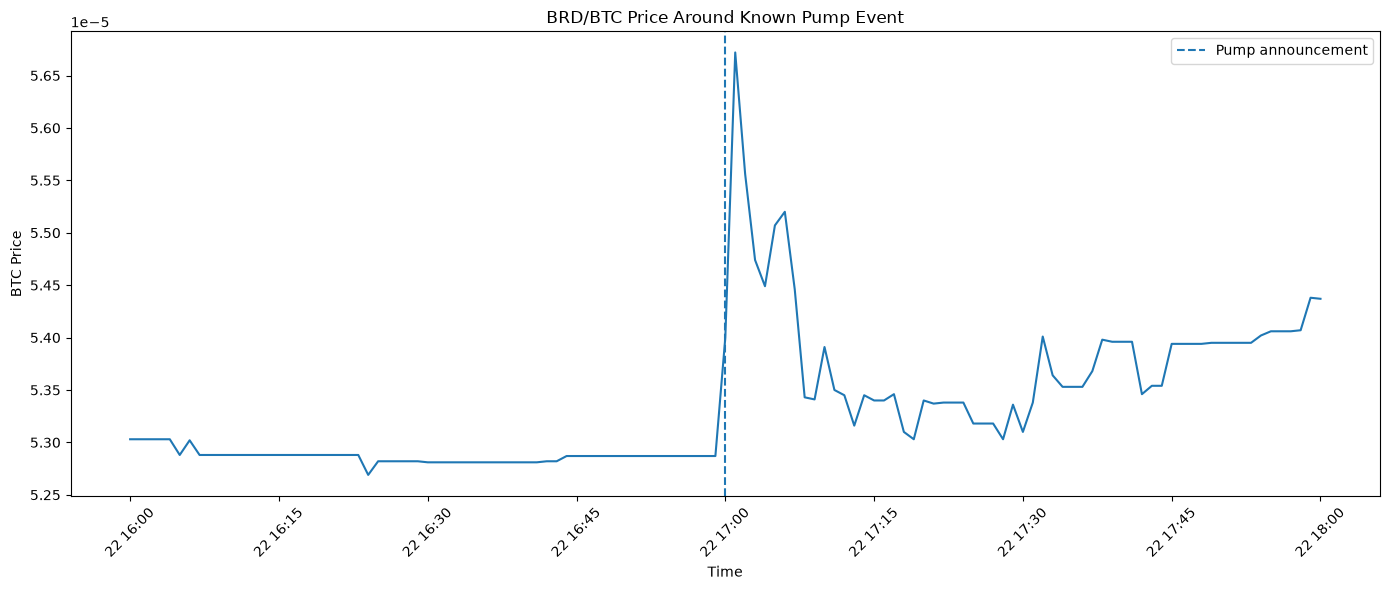

In [69]:
plt.figure(figsize=(14, 6))

plt.plot(
    event["datetime"],
    event["close"]
)

plt.axvline(
    pump_time,
    linestyle="--",
    label="Pump announcement"
)

plt.title("BRD/BTC Price Around Known Pump Event")
plt.xlabel("Time")
plt.ylabel("BTC Price")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

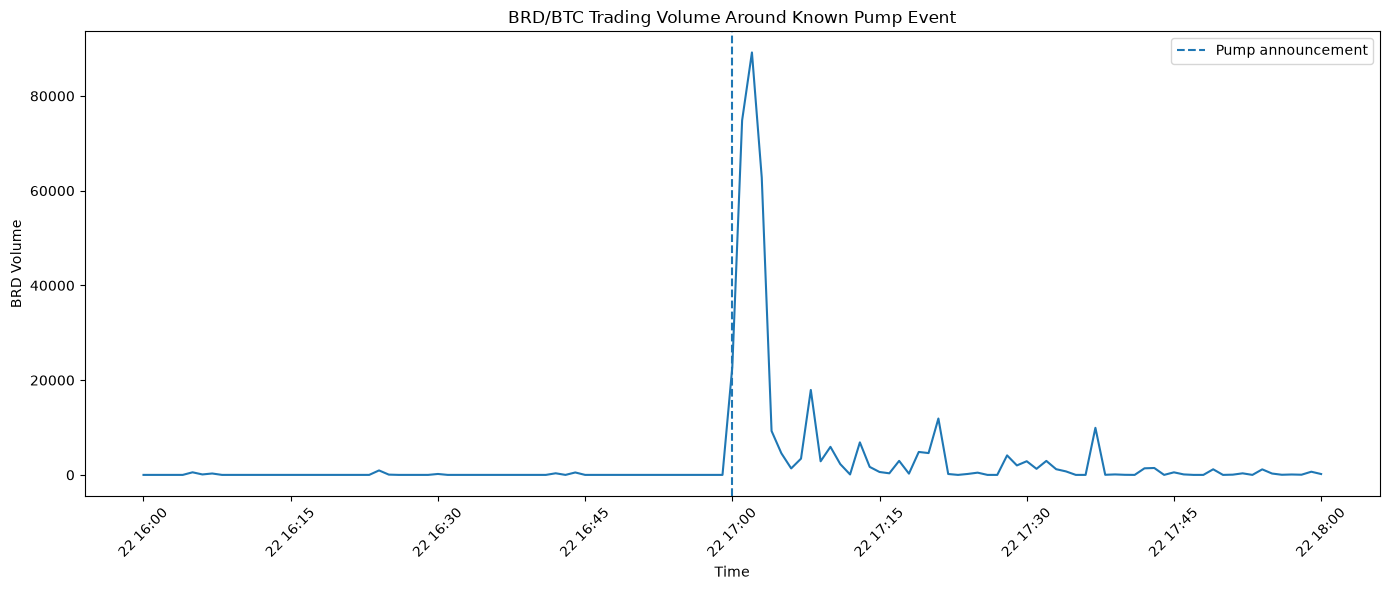

In [70]:
plt.figure(figsize=(14, 6))

plt.plot(
    event["datetime"],
    event["volume"]
)

plt.axvline(
    pump_time,
    linestyle="--",
    label="Pump announcement"
)

plt.title("BRD/BTC Trading Volume Around Known Pump Event")
plt.xlabel("Time")
plt.ylabel("BRD Volume")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

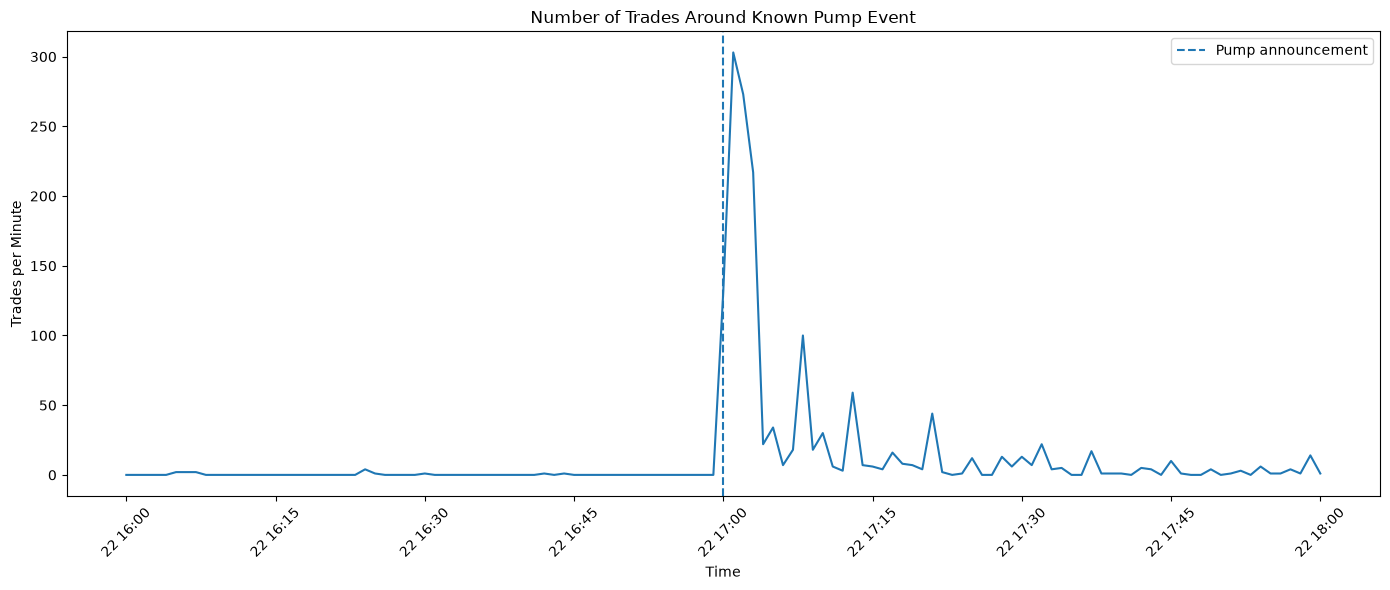

In [71]:
plt.figure(figsize=(14, 6))

plt.plot(event["datetime"],event["number_of_trades"])

plt.axvline(
    pump_time,
    linestyle="--",
    label="Pump announcement"
)

plt.title("Number of Trades Around Known Pump Event")
plt.xlabel("Time")
plt.ylabel("Trades per Minute")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [72]:
event[
    [
        "datetime",
        "close",
        "volume",
        "number_of_trades"
    ]
].iloc[50:71]

,datetime,close,volume,number_of_trades
31250,2018-12-22 16:50:00,0.000053,0.0,0
31251,2018-12-22 16:51:00,0.000053,0.0,0
31252,2018-12-22 16:52:00,0.000053,0.0,0
31253,2018-12-22 16:53:00,0.000053,0.0,0
31254,2018-12-22 16:54:00,0.000053,0.0,0
31255,2018-12-22 16:55:00,0.000053,0.0,0
31256,2018-12-22 16:56:00,0.000053,0.0,0
31257,2018-12-22 16:57:00,0.000053,0.0,0
31258,2018-12-22 16:58:00,0.000053,0.0,0
31259,2018-12-22 16:59:00,0.000053,0.0,0


In [73]:
event.loc[
    event["volume"].idxmax(),
    ["datetime", "close", "volume", "number_of_trades"]
]

datetime            2018-12-22 17:02:00
close                          0.000056
volume                          89184.0
number_of_trades                    273
Name: 31262, dtype: object

In [74]:
event.loc[
    event["high"].idxmax(),
    ["datetime", "high", "volume", "number_of_trades"]
]

datetime            2018-12-22 17:02:00
high                           0.000057
volume                          89184.0
number_of_trades                    273
Name: 31262, dtype: object

In [75]:
before_pump = event[
    (event["datetime"] >= pump_time - pd.Timedelta(minutes=30)) &
    (event["datetime"] < pump_time)
]

print("Average volume before pump:")
print(before_pump["volume"].mean())

print("\nAverage trades/min before pump:")
print(before_pump["number_of_trades"].mean())

print("\nVolume at price peak:")
print(89184)

print("\nTrades at price peak:")
print(273)

Average volume before pump:
34.9

Average trades/min before pump:
0.1

Volume at price peak:
89184

Trades at price peak:
273


In [76]:
df["return_1m"] = df["close"].pct_change()
df[
    ["datetime", "close", "return_1m"]
].loc[31255:31265]

,datetime,close,return_1m
31255,2018-12-22 16:55:00,0.000053,0.000000
31256,2018-12-22 16:56:00,0.000053,0.000000
31257,2018-12-22 16:57:00,0.000053,0.000000
31258,2018-12-22 16:58:00,0.000053,0.000000
31259,2018-12-22 16:59:00,0.000053,0.000000
31260,2018-12-22 17:00:00,0.000054,0.021373
31261,2018-12-22 17:01:00,0.000057,0.050370
31262,2018-12-22 17:02:00,0.000056,-0.020451
31263,2018-12-22 17:03:00,0.000055,-0.014759
31264,2018-12-22 17:04:00,0.000054,-0.004567


In [77]:
df["return_5m"] = df["close"].pct_change(5)
df[
    ["datetime", "close", "return_5m"]
].loc[31255:31265]

,datetime,close,return_5m
31255,2018-12-22 16:55:00,0.000053,0.000000
31256,2018-12-22 16:56:00,0.000053,0.000000
31257,2018-12-22 16:57:00,0.000053,0.000000
31258,2018-12-22 16:58:00,0.000053,0.000000
31259,2018-12-22 16:59:00,0.000053,0.000000
31260,2018-12-22 17:00:00,0.000054,0.021373
31261,2018-12-22 17:01:00,0.000057,0.072820
31262,2018-12-22 17:02:00,0.000056,0.050880
31263,2018-12-22 17:03:00,0.000055,0.035370
31264,2018-12-22 17:04:00,0.000054,0.030641


In [79]:
df["volume_mean_30min"] = (df["volume"].rolling(30).mean().shift(1))
df["log_volume_ratio"] = np.log1p(
    df["volume"] /
    (df["volume_mean_30min"] + 1e-8)
)


In [84]:
df["trades_mean_30m"] = (
    df["number_of_trades"]
    .rolling(30)
    .mean()
    .shift(1)
)

df["log_trades_ratio"] = np.log1p(
    df["number_of_trades"] /
    (df["trades_mean_30m"] + 1e-8)
)

In [85]:
df["volatility_10m"] = (
    df["return_1m"]
    .rolling(10)
    .std()
    .shift(1)
)

In [90]:
df["candle_range"] = (
    (df["high"] - df["low"]) /
    df["open"]
)

df["taker_buy_ratio"] = (
    df["taker_buy_base_volume"] /
    (df["volume"] + 1e-8)
)

In [91]:
event = df[
    (df["datetime"] >= pump_time - pd.Timedelta(minutes=5)) &
    (df["datetime"] <= pump_time + pd.Timedelta(minutes=5))
].copy()

event[
    [
        "datetime",
        "return_1m",
        "return_5m",
        "log_volume_ratio",
        "log_trades_ratio",
        "candle_range",
        "taker_buy_ratio"
    ]
]
# A high candle range - unusual before

,datetime,return_1m,return_5m,log_volume_ratio,log_trades_ratio,candle_range,taker_buy_ratio
31255,2018-12-22 16:55:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
31256,2018-12-22 16:56:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
31257,2018-12-22 16:57:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
31258,2018-12-22 16:58:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
31259,2018-12-22 16:59:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
31260,2018-12-22 17:00:00,0.021373,0.021373,6.483383,7.186144,0.024340,0.611467
31261,2018-12-22 17:01:00,0.050370,0.072820,4.563897,4.231724,0.051842,0.608660
31262,2018-12-22 17:02:00,-0.020451,0.050880,3.338045,2.982719,0.034379,0.205115
31263,2018-12-22 17:03:00,-0.014759,0.035370,2.401063,2.319345,0.031199,0.739096
31264,2018-12-22 17:04:00,-0.004567,0.030641,0.747147,0.537647,0.010597,0.625013
